# Лабораторная работа №16: Визуальные токенизаторы и autoregressive image generation

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Обучить compact VQ-VAE.
- Измерить reconstruction и codebook utilization.
- Обучить autoregressive prior и сравнить sampling.

## Теоретическая часть

VQ-VAE кодирует изображение в grid latent vectors, заменяет каждый ближайшим codebook vector и декодирует. Индексы становятся visual tokens для autoregressive prior. Малый codebook ухудшает reconstruction, большой может иметь dead codes.

![VQ-VAE](https://raw.githubusercontent.com/CompVis/taming-transformers/master/assets/teaser.png)


VQ-VAE заменяет пространственные признаки ближайшими векторами кодбука, straight-through переносит градиент через дискретизацию. Conditional autoregressive prior предсказывает очередной visual token по уже известным индексам и метке класса.

Для индекса $k^*=\arg\min_k\|z_e-e_k\|_2^2$ straight-through задаёт $z_q=z_e+\operatorname{sg}(e_{k^*}-z_e)$. Perplexity кодов равна $\exp(-\sum_k p_k\log p_k)$.

### Экспериментальный протокол

MNIST train 20 000/test 2 000; 28×28→7×7 visual tokens. Два токенизатора K=16/64; обученный conditional Transformer; 1000 шагов каждого в полном режиме. Smoke 2 шага — только техническая проверка.

### Материалы

- [VQ-VAE](https://arxiv.org/abs/1711.00937)
- [Taming Transformers](https://github.com/CompVis/taming-transformers)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
SEED = 42
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
# локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', str(Path.cwd().parents[1] / 'data')))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'mps', 'fast_dev_run': False, 'artifacts': 'artifacts'}


### Архитектура дискретного токенизатора

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами.

**Результат.** Проверяемое состояние «Архитектура дискретного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами» и его результат доступен следующему этапу.

In [2]:
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, TensorDataset

mnist_train = torchvision.datasets.MNIST(DATA_ROOT, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True)
N_TRAIN, N_TEST = 20000, 2000
X_train = mnist_train.data[:N_TRAIN].float().div(255).unsqueeze(1); y_train = mnist_train.targets[:N_TRAIN]
X_test = mnist_test.data[:N_TEST].float().div(255).unsqueeze(1); y_test = mnist_test.targets[:N_TEST]

class VectorQuantizer(nn.Module):
    def __init__(self, K, D, beta=0.25):
        super().__init__()
        self.K, self.D, self.beta = K, D, beta
        self.codebook = nn.Embedding(K, D)
        self.codebook.weight.data.uniform_(-1 / K, 1 / K)
    def forward(self, z_e):                                   # z_e: [B, D, H, W]
        z = z_e.permute(0, 2, 3, 1).reshape(-1, self.D)
        d = (z.pow(2).sum(1, keepdim=True) - 2 * z @ self.codebook.weight.T + self.codebook.weight.pow(2).sum(1)[None])
        idx = d.argmin(1)                                    # ближайший код
        z_q = self.codebook(idx).view(z_e.shape[0], z_e.shape[2], z_e.shape[3], self.D).permute(0, 3, 1, 2)
        codebook_loss = F.mse_loss(z_q, z_e.detach())           # тянет коды к энкодеру
        commit_loss = F.mse_loss(z_e, z_q.detach())             # удерживает энкодер у выбранного кода
        z_q_st = z_e + (z_q - z_e).detach()                     # straight-through: z_q = z_e + sg(e_k − z_e)
        return z_q_st, idx.view(z_e.shape[0], -1), codebook_loss + self.beta * commit_loss

class VQVAE(nn.Module):
    """28×28 → 7×7 токенов; энкодер и декодер свёрточные."""
    def __init__(self, K=64, D=64, ch=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(1, ch, 4, 2, 1), nn.ReLU(), nn.Conv2d(ch, 2 * ch, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(2 * ch, 2 * ch, 3, 1, 1), nn.ReLU(), nn.Conv2d(2 * ch, D, 1))
        self.vq = VectorQuantizer(K, D)
        self.dec = nn.Sequential(nn.Conv2d(D, 2 * ch, 3, 1, 1), nn.ReLU(), nn.ConvTranspose2d(2 * ch, ch, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(ch, 1, 4, 2, 1))
    def encode(self, x):
        return self.vq(self.enc(x))
    def decode_indices(self, idx):                            # idx: [B, 49]
        z_q = self.vq.codebook(idx).view(idx.shape[0], 7, 7, -1).permute(0, 3, 1, 2)
        return torch.sigmoid(self.dec(z_q))
    def forward(self, x):
        z_q, idx, vq_loss = self.encode(x)
        x_hat = torch.sigmoid(self.dec(z_q))
        return x_hat, idx, vq_loss

def vqvae_loss(x, x_hat, vq_loss):
    recon = F.mse_loss(x_hat, x)         # среднее по пикселям — тот же масштаб, что у слагаемых VQ (среднее по элементам)
    return recon + vq_loss, recon

_m = VQVAE(K=16).to(DEVICE)
_x_hat, _idx, _l = _m(X_train[:4].to(DEVICE))
assert _x_hat.shape == (4, 1, 28, 28) and _idx.shape == (4, 49) and int(_idx.max()) < 16
print("VQ-VAE: вход 28×28 → сетка 7×7 = 49 токенов; параметров", sum(p.numel() for p in _m.parameters()))

VQ-VAE: вход 28×28 → сетка 7×7 = 49 токенов; параметров 495169


### Обучение и диагностика двух кодбуков

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint.

**Результат.** Проверяемое состояние «Обучение и диагностика двух кодбуков» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint» и его результат доступен следующему этапу.

    test_mse used dead perplexity bits_per_image train_seconds
16  0.005784   16    0  11.885328          196.0      7.645894
64  0.004995   35   29  17.089741          294.0       7.74183


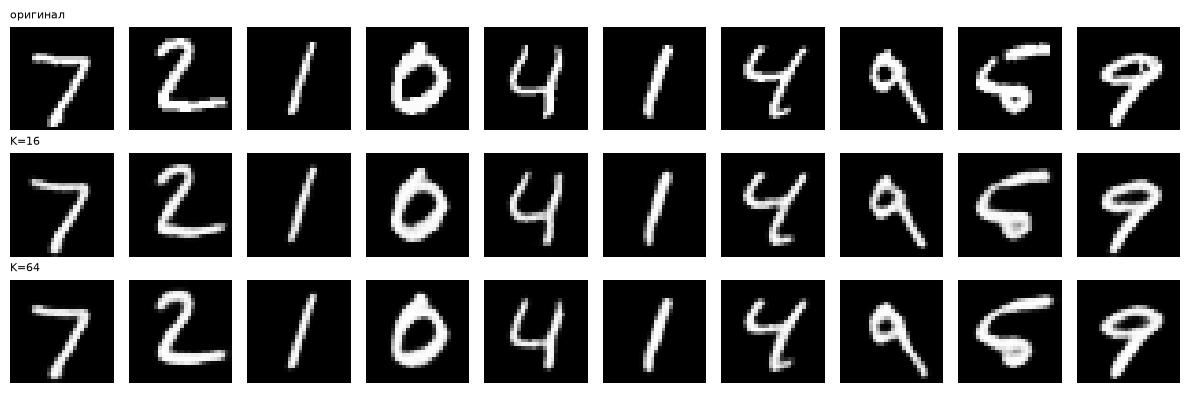

In [3]:
STEPS = 2 if FAST_DEV_RUN else 1000
BATCH = 128

def code_stats(idx, K):
    counts = torch.bincount(idx.flatten(), minlength=K).double()
    p = counts / counts.sum()
    nz = p[p > 0]
    return {"used": int((counts > 0).sum()), "dead": int((counts == 0).sum()), "perplexity": float(torch.exp(-(nz * nz.log()).sum())),
            "top5_codes": torch.argsort(counts, descending=True)[:5].tolist(), "top5_freq": (torch.sort(p, descending=True).values[:5]).tolist()}

def train_vqvae(K, steps=STEPS, seed=SEED):
    path = ARTIFACTS / f"vqvae_K{K}{'_smoke' if FAST_DEV_RUN else ''}.pt"
    torch.manual_seed(seed)
    model = VQVAE(K=K).to(DEVICE)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=DEVICE)["model"]); return model, torch.load(path, weights_only=False)["history"]
    with torch.no_grad():   # инициализация кодбука выходами энкодера на случайных train-векторах
        z = model.enc(X_train[:512].to(DEVICE)).permute(0, 2, 3, 1).reshape(-1, model.vq.D)
        model.vq.codebook.weight.copy_(z[torch.randperm(len(z), generator=torch.Generator().manual_seed(seed))[:K].to(z.device)])
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train), batch_size=BATCH, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(seed))
    hist, step = [], 0
    while step < steps:
        for (x,) in loader:
            x = x.to(DEVICE)
            x_hat, _, vq_l = model(x)
            loss, recon = vqvae_loss(x, x_hat, vq_l)
            opt.zero_grad(); loss.backward(); opt.step()
            hist.append({"loss": loss.item(), "recon": recon.item()}); step += 1
            if step >= steps:
                break
    torch.save({"model": model.state_dict(), "optimizer": opt.state_dict(), "history": hist, "K": K, "steps": steps}, path)
    return model, hist

@torch.no_grad()
def evaluate_vqvae(model, X, K):
    model.eval()
    mse, idxs = [], []
    for i in range(0, len(X), 500):
        x = X[i:i + 500].to(DEVICE)
        x_hat, idx, _ = model(x)
        mse.append(F.mse_loss(x_hat, x, reduction="none").mean((1, 2, 3)).cpu()); idxs.append(idx.cpu())
    mse, idxs = torch.cat(mse), torch.cat(idxs)
    return {"test_mse": float(mse.mean()), **code_stats(idxs, K)}, mse, idxs

tokenizers, tok_report = {}, {}
for K in (16, 64):
    t0 = time.time()
    m, h = train_vqvae(K)
    rep, mse_per_img, _ = evaluate_vqvae(m, X_test, K)
    _, _, train_idx_K = evaluate_vqvae(m, X_train[:5000], K)
    rep.update(train_seconds=time.time() - t0, final_train_recon=float(np.mean([r["recon"] for r in h[-50:]])), steps=len(h),
               dead_on_train5000=code_stats(train_idx_K, K)["dead"], tokens_per_image=49, bits_per_image=49 * float(np.log2(K)))
    tokenizers[K], tok_report[K] = m, rep
save_json("tokenizers.json", tok_report)
import pandas as pd
print(pd.DataFrame(tok_report).T[["test_mse", "used", "dead", "perplexity", "bits_per_image", "train_seconds"]].to_string())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
with torch.no_grad():
    rec16 = tokenizers[16](X_test[:10].to(DEVICE))[0].cpu(); rec64 = tokenizers[64](X_test[:10].to(DEVICE))[0].cpu()
for c in range(10):
    for r, img in enumerate((X_test[c], rec16[c], rec64[c])):
        axes[r, c].imshow(img[0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
for r, name in enumerate(("оригинал", "K=16", "K=64")):
    axes[r, 0].set_title(name, fontsize=8, loc="left")
fig.tight_layout(); fig.savefig(ARTIFACTS / "reconstructions.png", dpi=110); plt.show()

### Индексы обученного токенизатора

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Закодируйте train/test только обученной VQ-VAE K=64.

**Результат.** Проверяемое состояние «Индексы обученного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Закодируйте train/test только обученной VQ-VAE K=64» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Причинная маска prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов.

**Результат.** Проверяемое состояние «Причинная маска prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Обучение autoregressive prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте CE сдвинутой последовательности с checkpoint.

**Результат.** Проверяемое состояние «Обучение autoregressive prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте CE сдвинутой последовательности с checkpoint» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Cross-entropy на test токенах

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оцените CE независимых test токенов без обновления весов.

**Результат.** Проверяемое состояние «Cross-entropy на test токенах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оцените CE независимых test токенов без обновления весов» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Архитектура проверяющего классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную сеть для class agreement.

**Результат.** Проверяемое состояние «Архитектура проверяющего классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную сеть для class agreement» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Обучение и реальный test классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите на train и проверьте точность на независимом real test.

**Результат.** Проверяемое состояние «Обучение и реальный test классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите на train и проверьте точность на независимом real test» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Фильтрация и семплирование токенов

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно.

**Результат.** Проверяемое состояние «Фильтрация и семплирование токенов» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Декодированная генерация и проверка

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения.

**Результат.** Проверяемое состояние «Декодированная генерация и проверка» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения» и его результат доступен следующему этапу.

In [ ]:
# Реализуйте это задание по постановке выше.
# Сохраните перечисленные артефакты и выведите фактически измеренные значения.
raise NotImplementedError("Реализуйте это задание в этой ячейке")

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.